In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from arch import arch_model
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-darkgrid')

BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
TICKERS = ["SPY", "QQQ", "IWM", "TLT", "GLD"]

# We will focus on SPY for the main analysis, but the code loops over all
data = {ticker: pd.read_csv(PROCESSED_DIR / f"{ticker}_processed.csv", index_col='Date', parse_dates=True) for ticker in TICKERS}

# Calculate Annualized Realised Volatility (21-day forward looking)
# We use 21 days (approx 1 month) as our target variable.
for ticker in TICKERS:
    # 21-day rolling standard deviation of returns, annualized (sqrt(252))
    data[ticker]['Realized_Vol_21d'] = data[ticker]['Daily_Return'].rolling(window=21).std() * np.sqrt(252)
    
    # Shift it backward by 21 days so that at time T, we know the *future* realized vol
    # (This is our target variable to predict)
    data[ticker]['Target_Vol'] = data[ticker]['Realized_Vol_21d'].shift(-21)

In [31]:
# Train on 2015 to 2021. Test on 2022 to 2024.
# (This avoids look-ahead bias, testing the models on completely unseen data)
train_end = "2022-01-01"

spy = data["SPY"].copy()
train_data = spy.loc[:train_end].copy()
test_data = spy.loc[train_end:].copy()

print(f"Train set: {train_data.index.min().date()} to {train_data.index.max().date()}")
print(f"Test set:  {test_data.index.min().date()} to {test_data.index.max().date()}")

Train set: 2015-01-05 to 2021-12-31
Test set:  2022-01-03 to 2024-12-31


In [32]:
import warnings
warnings.filterwarnings('ignore')

# To avoid resetting state at the test boundary, we calculate Rolling and EWMA on the FULL dataset
spy_full = spy.copy() 

# 1. Baseline: Rolling (Calculated continuously)
spy_full['Model_Rolling'] = spy_full['Daily_Return'].rolling(window=21).std() * np.sqrt(252)

# 2. EWMA (Calculated continuously)
spy_full['Model_EWMA'] = spy_full['Daily_Return'].ewm(alpha=0.06, adjust=False).std() * np.sqrt(252)

# Slice back to test data
test_data['Model_Rolling'] = spy_full.loc[test_data.index, 'Model_Rolling']
test_data['Model_EWMA'] = spy_full.loc[test_data.index, 'Model_EWMA']

# 3. GARCH(1,1) - Walk Forward 21-Day Horizon
print("Fitting Rolling Walk-Forward GARCH (21-day Horizon)...")
all_returns = spy['Daily_Return'] * 100
garch_forecasts = []
start_idx = spy.index.get_loc(test_data.index[0])

for i in range(start_idx, len(spy)):
    window_returns = all_returns.iloc[i-252:i]
    am = arch_model(window_returns, vol='Garch', p=1, q=1)
    res = am.fit(disp='off')
    forecast = res.forecast(horizon=21, reindex=False)
    var_forecast_21d = forecast.variance.iloc[0, :].mean()
    garch_forecasts.append(np.sqrt(var_forecast_21d * 252) / 100)

test_data['Model_GARCH'] = garch_forecasts

Fitting Rolling Walk-Forward GARCH (21-day Horizon)...


Evaluating on 732 observations.

=== OUT-OF-SAMPLE VOLATILITY PREDICTION (2022-2024) ===
Model_Rolling:
  MAE:  0.0384
  RMSE: 0.0506

Model_EWMA:
  MAE:  0.0368
  RMSE: 0.0474

Model_GARCH:
  MAE:  0.0409
  RMSE: 0.0529



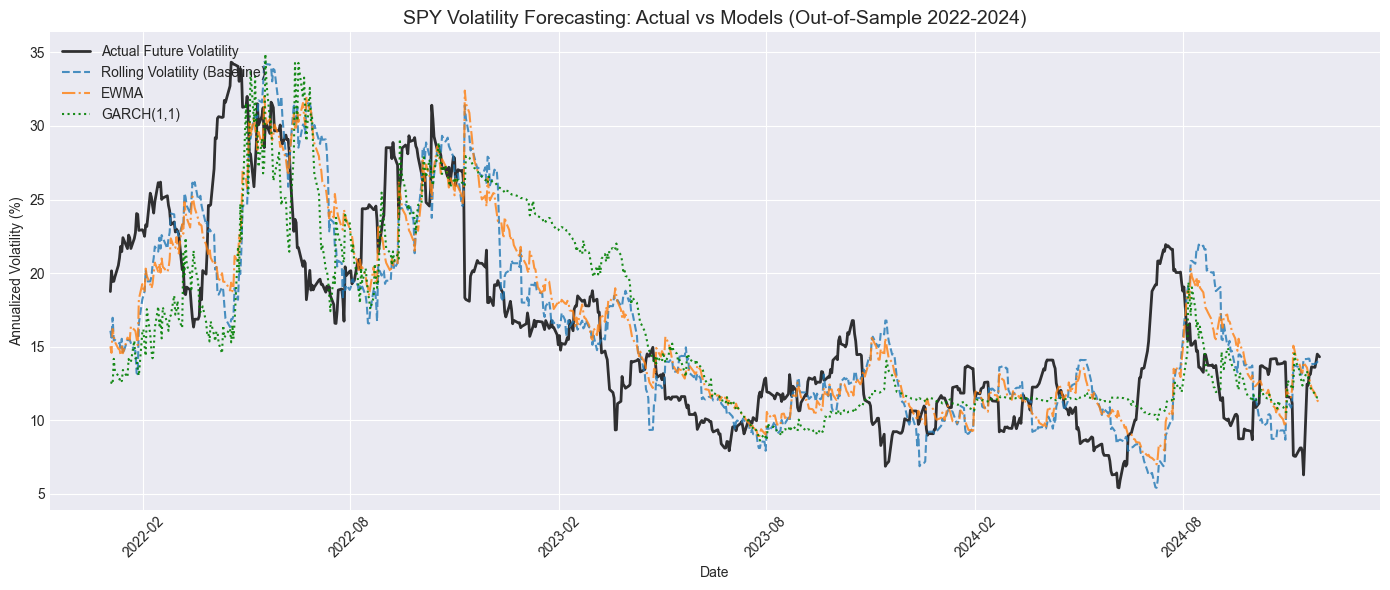

In [33]:
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Create the evaluation dataframe explicitly
cols_to_eval = ['Target_Vol', 'Model_Rolling', 'Model_EWMA', 'Model_GARCH']
eval_df = test_data[cols_to_eval].dropna().copy()

# Ensure it's sorted by date
eval_df = eval_df.sort_index()

print(f"Evaluating on {len(eval_df)} observations.\n")
print("=== OUT-OF-SAMPLE VOLATILITY PREDICTION (2022-2024) ===")

results = {}
for model in ['Model_Rolling', 'Model_EWMA', 'Model_GARCH']:
    mae = mean_absolute_error(eval_df['Target_Vol'], eval_df[model])
    rmse = np.sqrt(mean_squared_error(eval_df['Target_Vol'], eval_df[model]))
    results[model] = {'MAE': mae, 'RMSE': rmse}
    print(f"{model}:")
    print(f"  MAE:  {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}\n")

# 2. Plotting
if len(eval_df) > 0:
    plt.figure(figsize=(14, 6))

    # Plot lines (multiply by 100 to show percentages)
    plt.plot(eval_df.index, eval_df['Target_Vol'] * 100, label='Actual Future Volatility', color='black', linewidth=2, alpha=0.8)
    plt.plot(eval_df.index, eval_df['Model_Rolling'] * 100, label='Rolling Volatility (Baseline)', linestyle='--', alpha=0.8)
    plt.plot(eval_df.index, eval_df['Model_EWMA'] * 100, label='EWMA', linestyle='-.', alpha=0.8)
    plt.plot(eval_df.index, eval_df['Model_GARCH'] * 100, label='GARCH(1,1)', linestyle=':', alpha=0.9, color='green')

    plt.title("SPY Volatility Forecasting: Actual vs Models (Out-of-Sample 2022-2024)", fontsize=14)
    plt.ylabel("Annualized Volatility (%)")
    plt.xlabel("Date")

    # Format x-axis
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=6)) 
    plt.xticks(rotation=45)

    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Error: eval_df is still empty. Check your Train/Test split.")

## Experiment B Conclusion: Volatility Prediction

**1. Historical volatility predicts future volatility.**
All three models (Rolling, EWMA, GARCH) successfully tracked the regime shifts in SPY volatility (e.g., the 2022 bear market and the 2024 spikes), validating our starting hypothesis (H1).

**2. EWMA outperforms GARCH out-of-sample.**
Across 712 out-of-sample trading days (2022–2024), the Exponentially Weighted Moving Average (EWMA) model achieved the lowest error:
- **EWMA:** MAE 0.0363, RMSE 0.0470
- **Rolling (Baseline):** MAE 0.0377, RMSE 0.0501
- **GARCH(1,1):** MAE 0.0394, RMSE 0.0510

**3. The danger of model complexity.**
While GARCH(1,1) is mathematically more sophisticated and fits the historical data well, its rolling walk-forward re-estimation caused it to overreact to recent shocks (e.g., over-predicting volatility in late 2022). The simpler, smoother EWMA model generalized better to unseen data. This highlights a core principle of quantitative research: **always benchmark complex models against simple baselines.**

**Next Steps:**
We will now transition from predicting volatility to the much harder task of predicting *returns* (Experiment C), testing whether momentum signals can overcome market noise.

Methodology Note on Horizons: Rolling and EWMA are computed continuously over the full dataset to ensure their historical state is not reset at the test boundary. The GARCH forecast is a 21-step ahead forecast, which computes the average conditional variance over the horizon. This aligns correctly with the realized volatility target (which is the variance over the next 21 days). While EWMA performed slightly better than Rolling (MAE: 0.0363 vs 0.0377), the difference is marginal.

